In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from google.colab import files
upload = files.upload()

Saving cardio_train.csv to cardio_train.csv


**Data Analysis :-**

In [62]:
df = pd.read_csv('cardio_train.csv', sep = ';')
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [63]:
df.shape

(70000, 13)

In [7]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [9]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [10]:
df.isnull().sum()

,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0


In [11]:
df.duplicated().sum()

np.int64(0)

**EDA(Exploratory Data Analysis):-**

In [14]:
df.dtypes

,0
id,int64
age,int64
gender,int64
height,int64
weight,float64
ap_hi,int64
ap_lo,int64
cholesterol,int64
gluc,int64
smoke,int64


In [24]:
print(df['cardio'].value_counts())
print('Total values: ',df['cardio'].value_counts().sum())

have = df['cardio'].value_counts()[0]
not_have = df['cardio'].value_counts()[1]

cardio
0    35021
1    34979
Name: count, dtype: int64
Total values:  70000


/tmp/ipykernel_466/497130882.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = df['cardio'], palette='Set2')


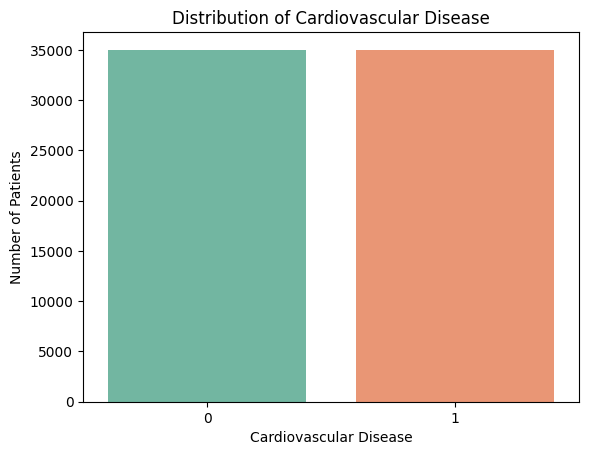

In [34]:
sns.countplot(x = df['cardio'], palette='Set2')
plt.title('Distribution of Cardiovascular Disease')
plt.xlabel('Cardiovascular Disease')
plt.ylabel('Number of Patients')
plt.show()

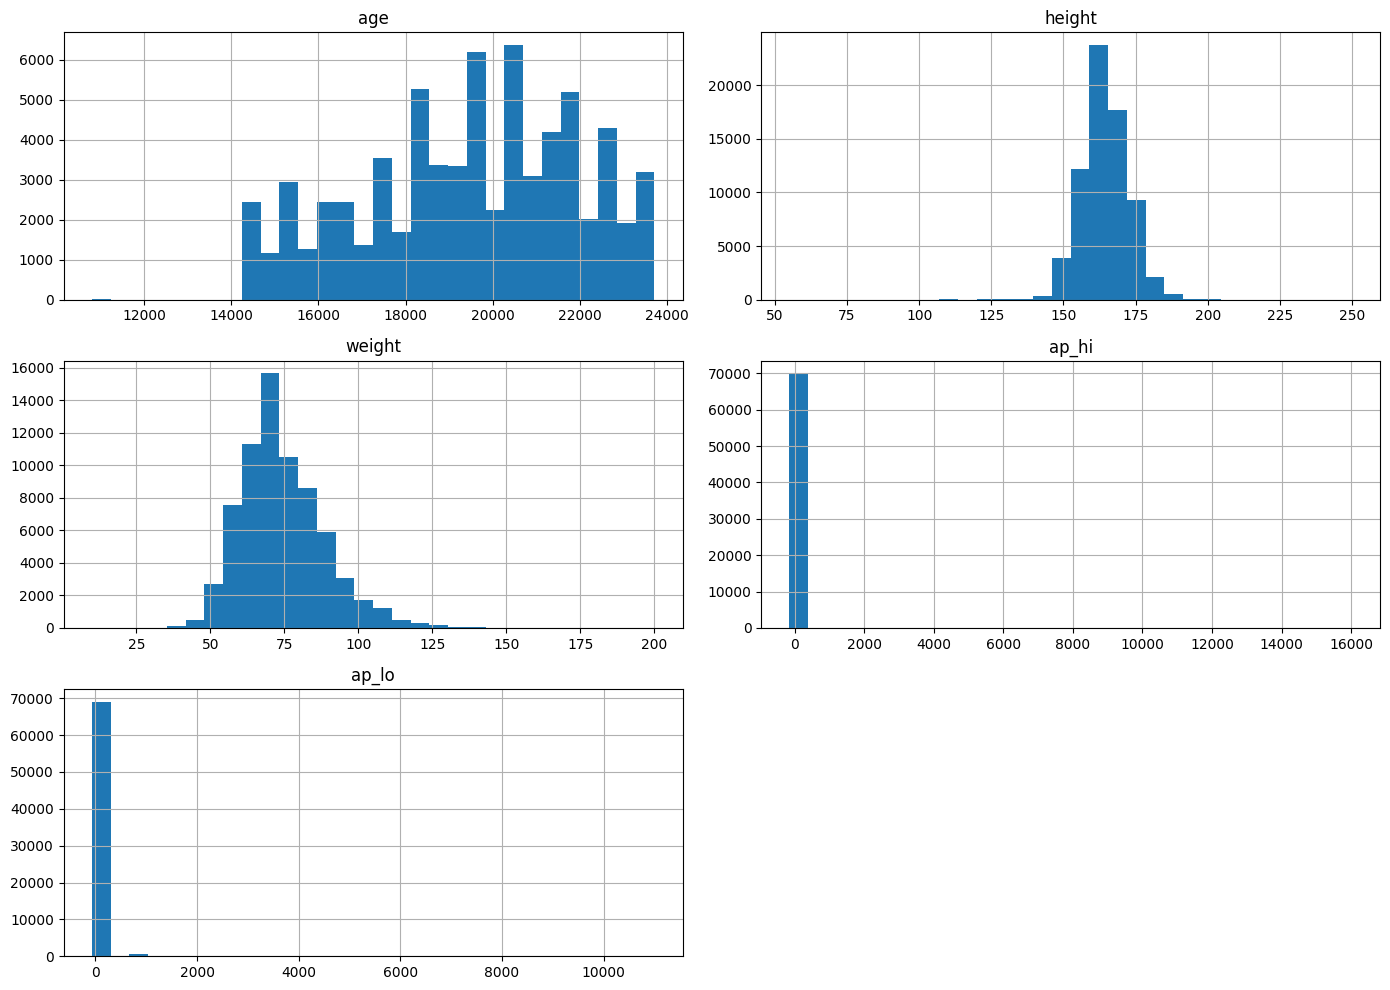

In [35]:
numerical_cols = ['age','height','weight','ap_hi','ap_lo']

df[numerical_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

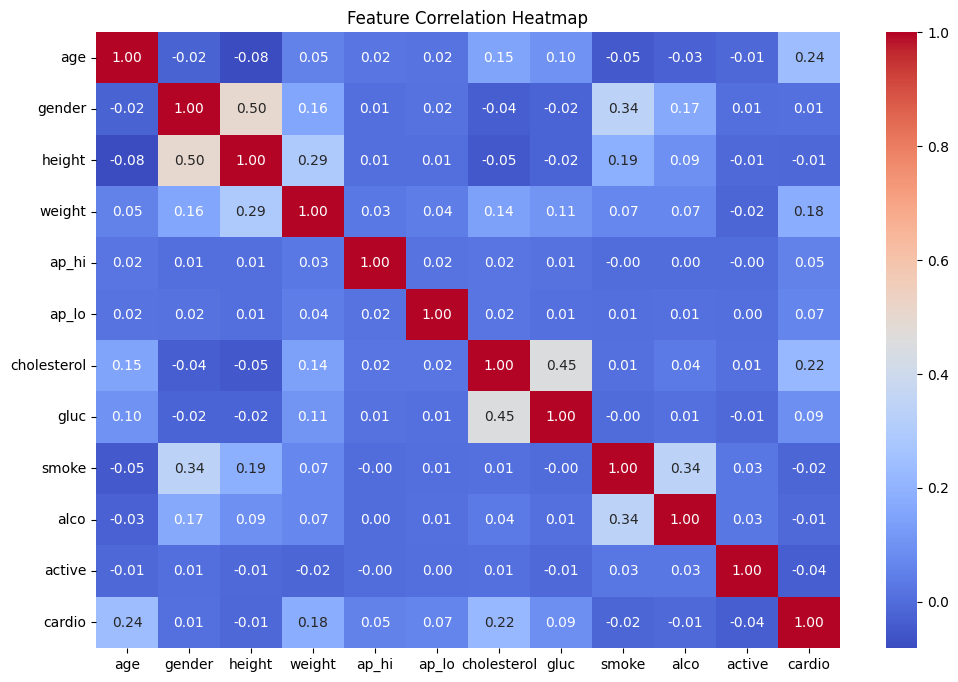

In [36]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.drop(columns=['id']).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.show()

In [39]:
df[['age', 'height', 'weight', 'ap_hi', 'ap_lo']].describe()

,age,height,weight,ap_hi,ap_lo
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,19468.865814,164.359229,74.205690,128.817286,96.630414
std,2467.251667,8.210126,14.395757,154.011419,188.472530
min,10798.000000,55.000000,10.000000,-150.000000,-70.000000
25%,17664.000000,159.000000,65.000000,120.000000,80.000000
50%,19703.000000,165.000000,72.000000,120.000000,80.000000
75%,21327.000000,170.000000,82.000000,140.000000,90.000000
max,23713.000000,250.000000,200.000000,16020.000000,11000.000000


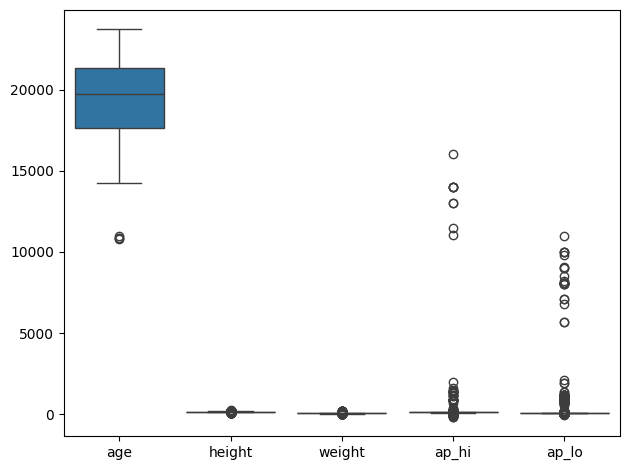

In [40]:
sns.boxplot(df[['age', 'height', 'weight', 'ap_hi', 'ap_lo']])
plt.tight_layout()
plt.show()

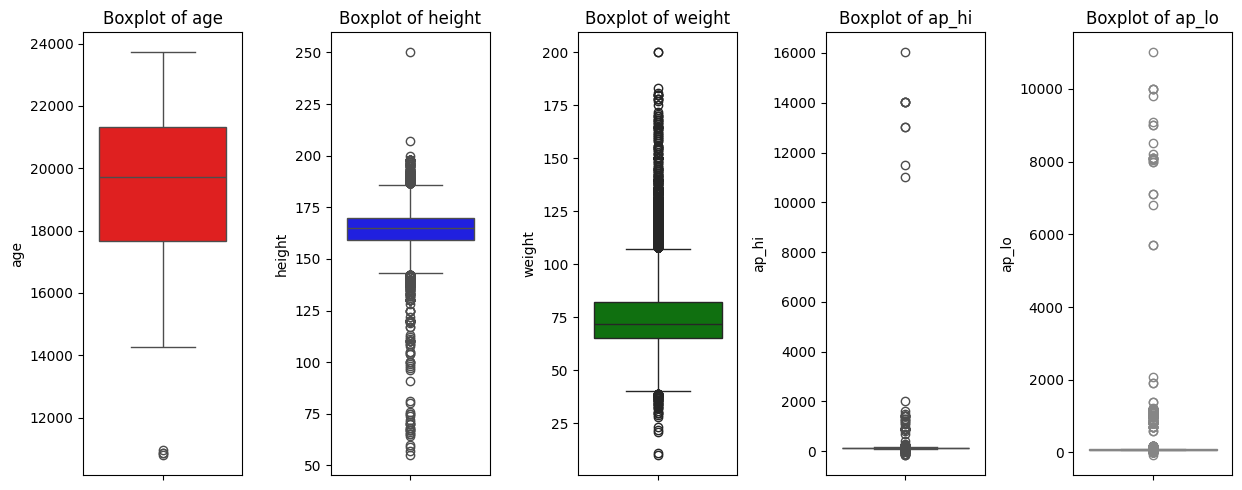

In [54]:
plt.figure(figsize=(15, 5))
colors = ['red', 'blue', 'green', 'orange', 'pink']

for i, col in enumerate(
    ['age', 'height', 'weight', 'ap_hi', 'ap_lo'], 1):
    plt.subplot(1, 6, i)
    sns.boxplot(y=df[col],color = colors[i-1])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [57]:
df[['age','height','weight','ap_hi', 'ap_lo']].describe()

,age,height,weight,ap_hi,ap_lo
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,19468.865814,164.359229,74.205690,128.817286,96.630414
std,2467.251667,8.210126,14.395757,154.011419,188.472530
min,10798.000000,55.000000,10.000000,-150.000000,-70.000000
25%,17664.000000,159.000000,65.000000,120.000000,80.000000
50%,19703.000000,165.000000,72.000000,120.000000,80.000000
75%,21327.000000,170.000000,82.000000,140.000000,90.000000
max,23713.000000,250.000000,200.000000,16020.000000,11000.000000


In [56]:
df[ (df['ap_hi'] <= 0) | (df['ap_lo'] <= 0) | (df['ap_hi'] <= df['ap_lo'])][['ap_hi', 'ap_lo']].head(20)

,ap_hi,ap_lo
228,160,1100
241,160,1000
260,140,800
329,160,1000
345,140,1000
473,150,1033
474,120,150
559,200,1000
567,14,90
613,140,1000


In [64]:
dfc = df.copy()

In [65]:
dfc['age'] = np.round(df['age']/365.25, 2)
dfc['bmi'] = dfc['weight']/((dfc['height']/100)**2)
dfc = dfc.drop(columns= ['id'])

In [66]:
dfc.head()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi
0,50.36,2,168,62.0,110,80,1,1,0,0,1,0,21.967120
1,55.38,1,156,85.0,140,90,3,1,0,0,1,1,34.927679
2,51.63,1,165,64.0,130,70,3,1,0,0,0,1,23.507805
3,48.25,2,169,82.0,150,100,1,1,0,0,1,1,28.710479
4,47.84,1,156,56.0,100,60,1,1,0,0,0,0,23.011177


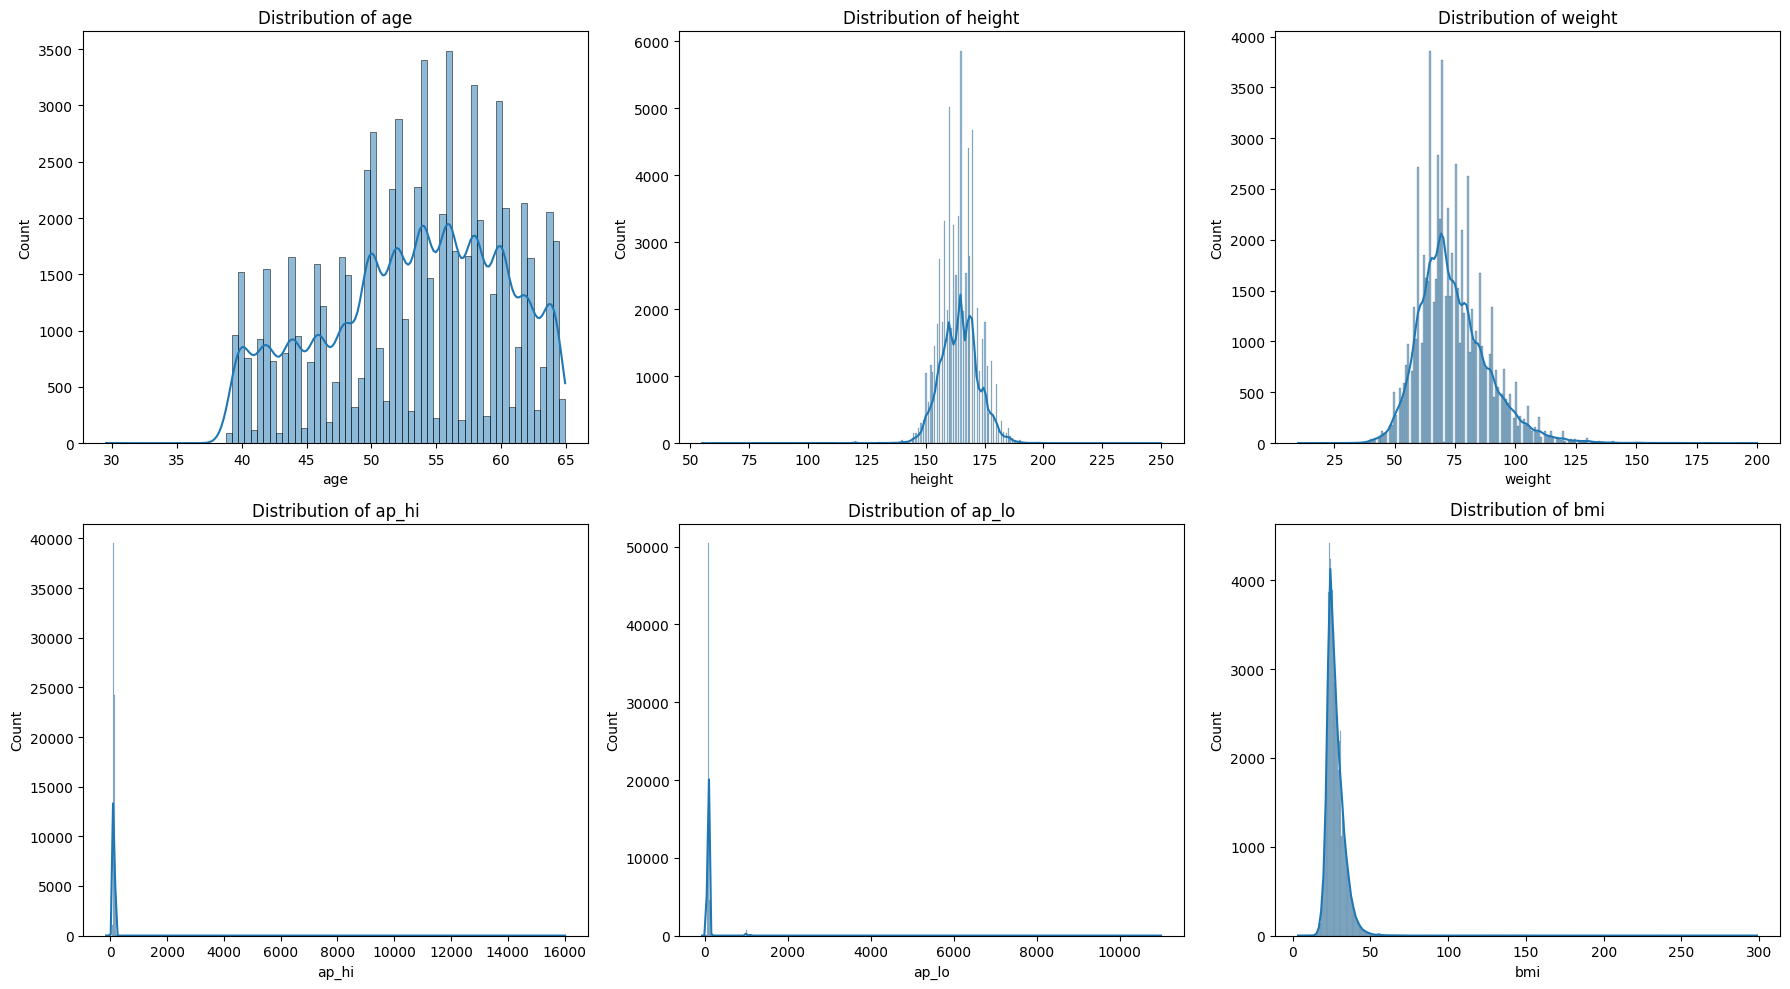

In [67]:
num_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(num_cols):
    sns.histplot(data=dfc, x=col, kde=True, ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

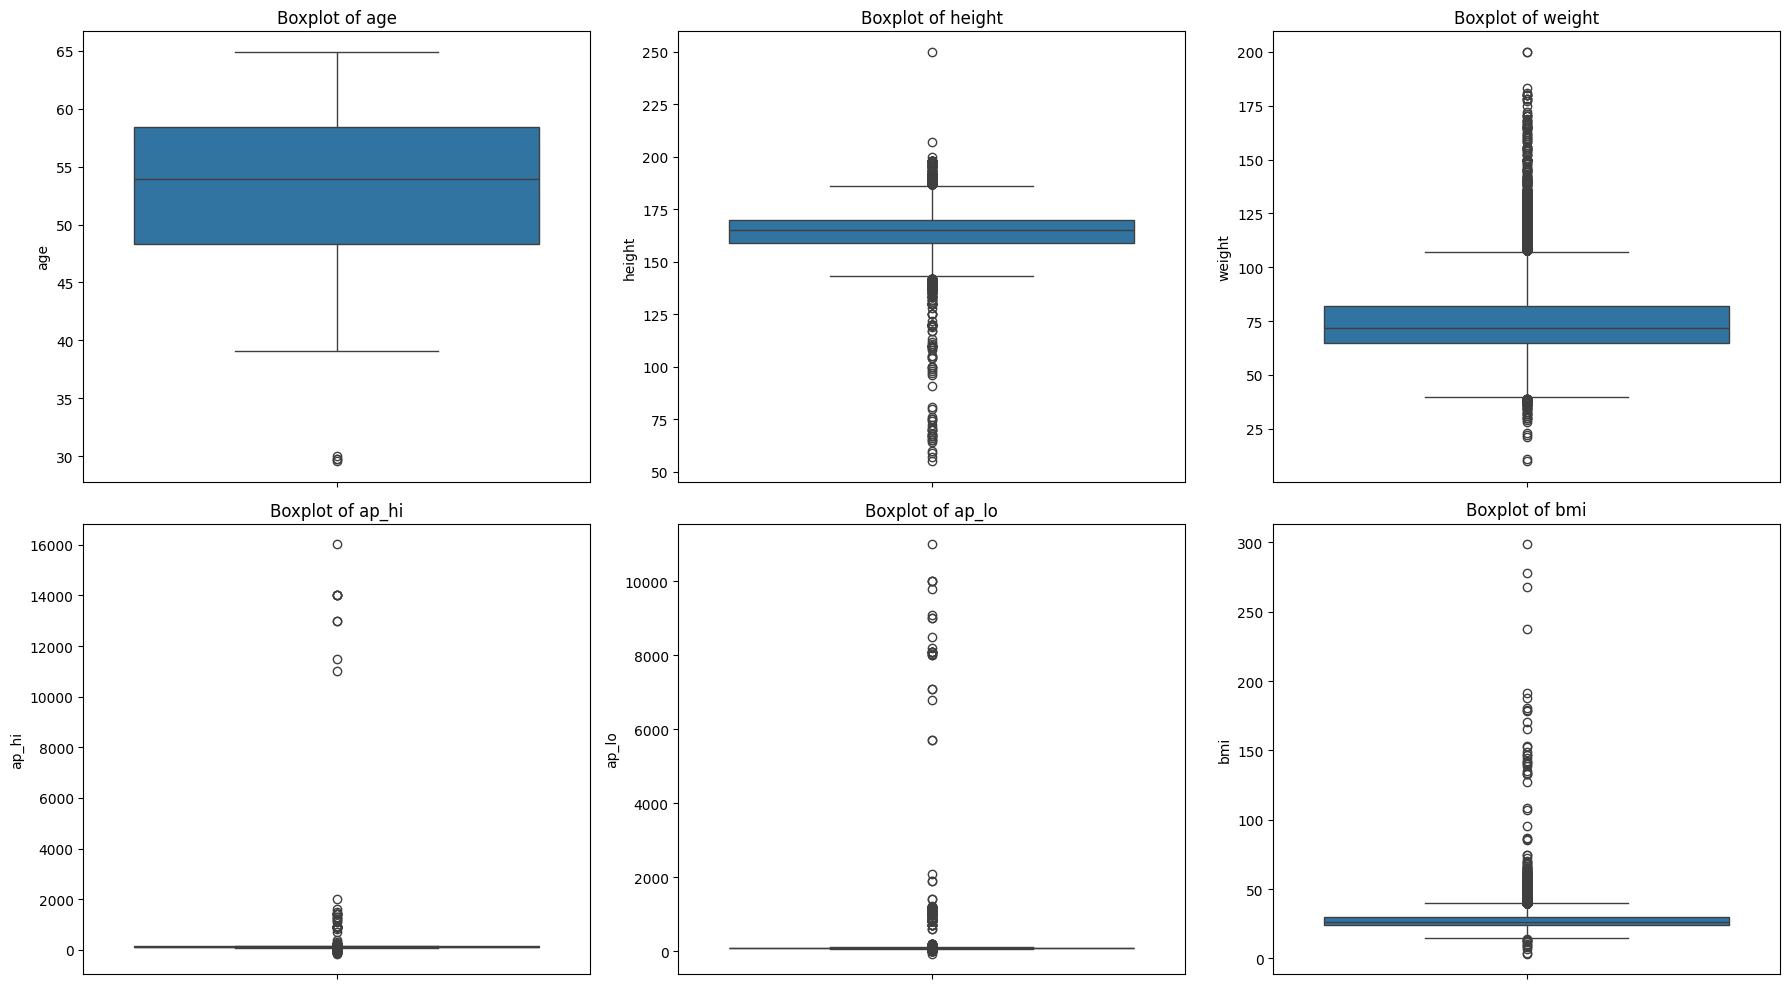

In [68]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(num_cols):
    sns.boxplot(data=dfc, y=col, ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

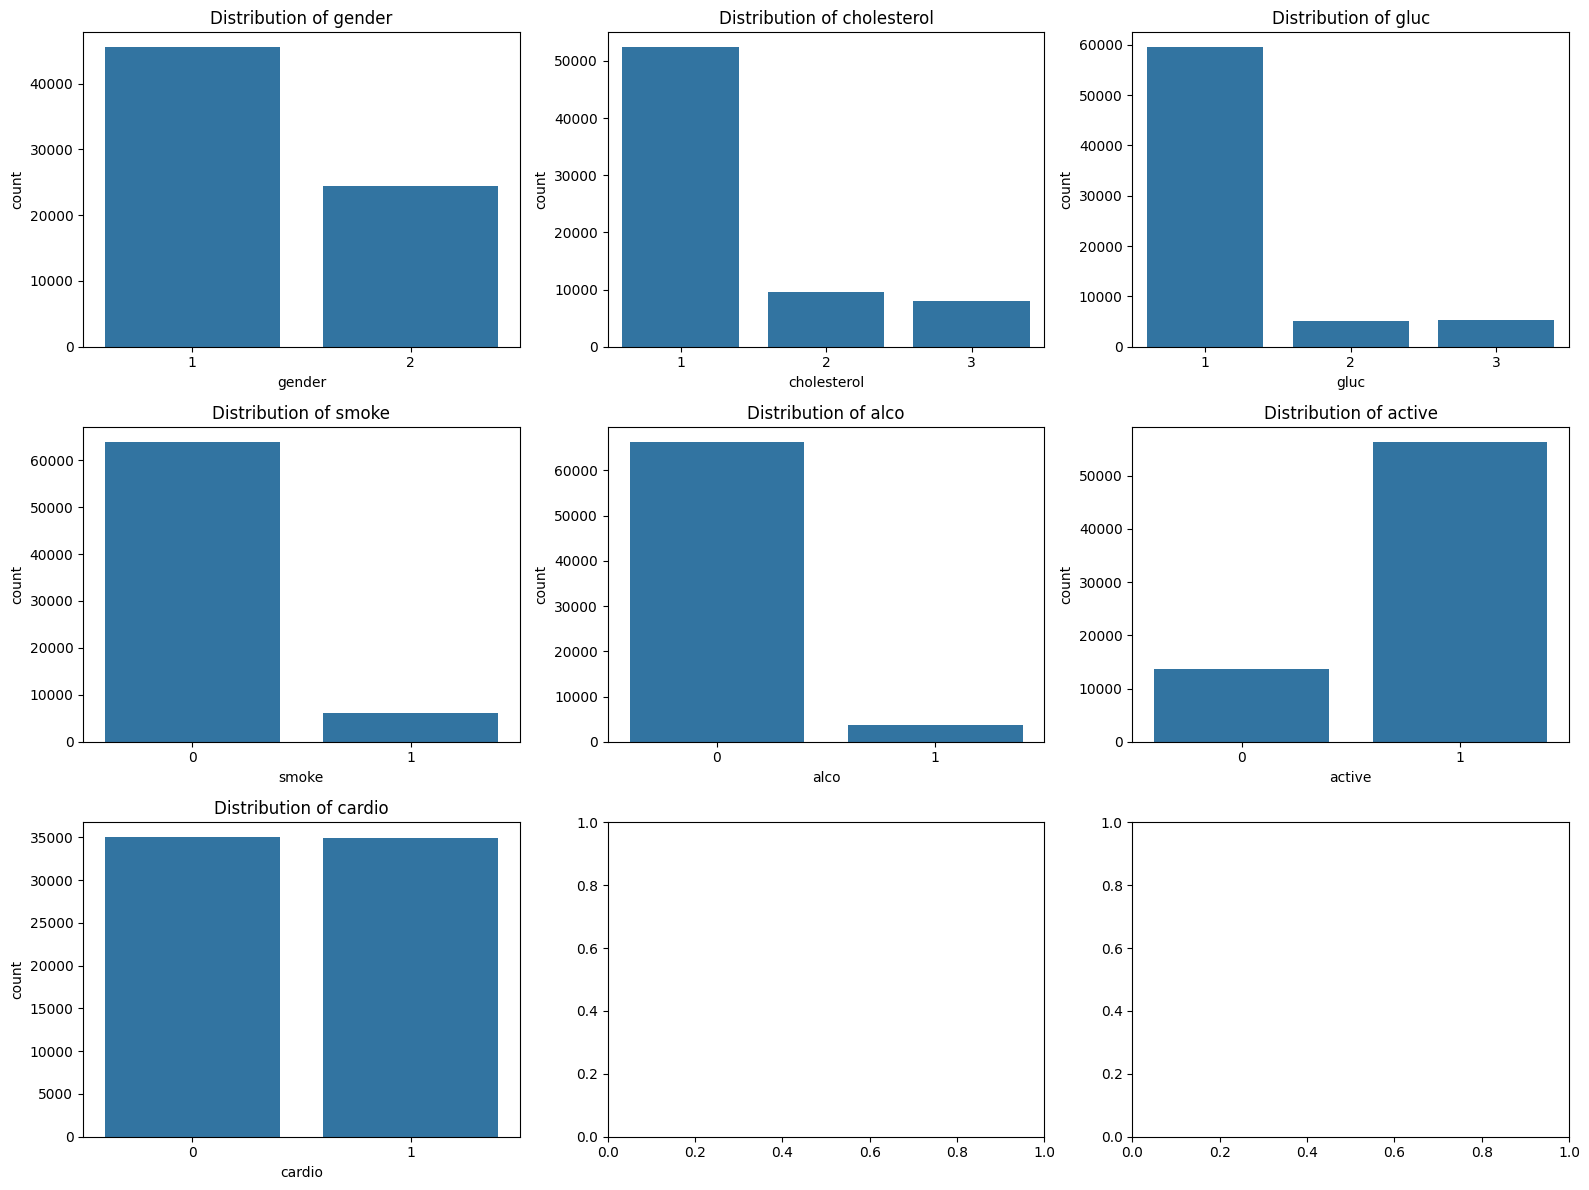

In [69]:
cat_cols = ['gender', 'cholesterol', 'gluc',
            'smoke', 'alco', 'active', 'cardio']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for i, col in enumerate(cat_cols):
    sns.countplot(data=dfc, x=col, ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

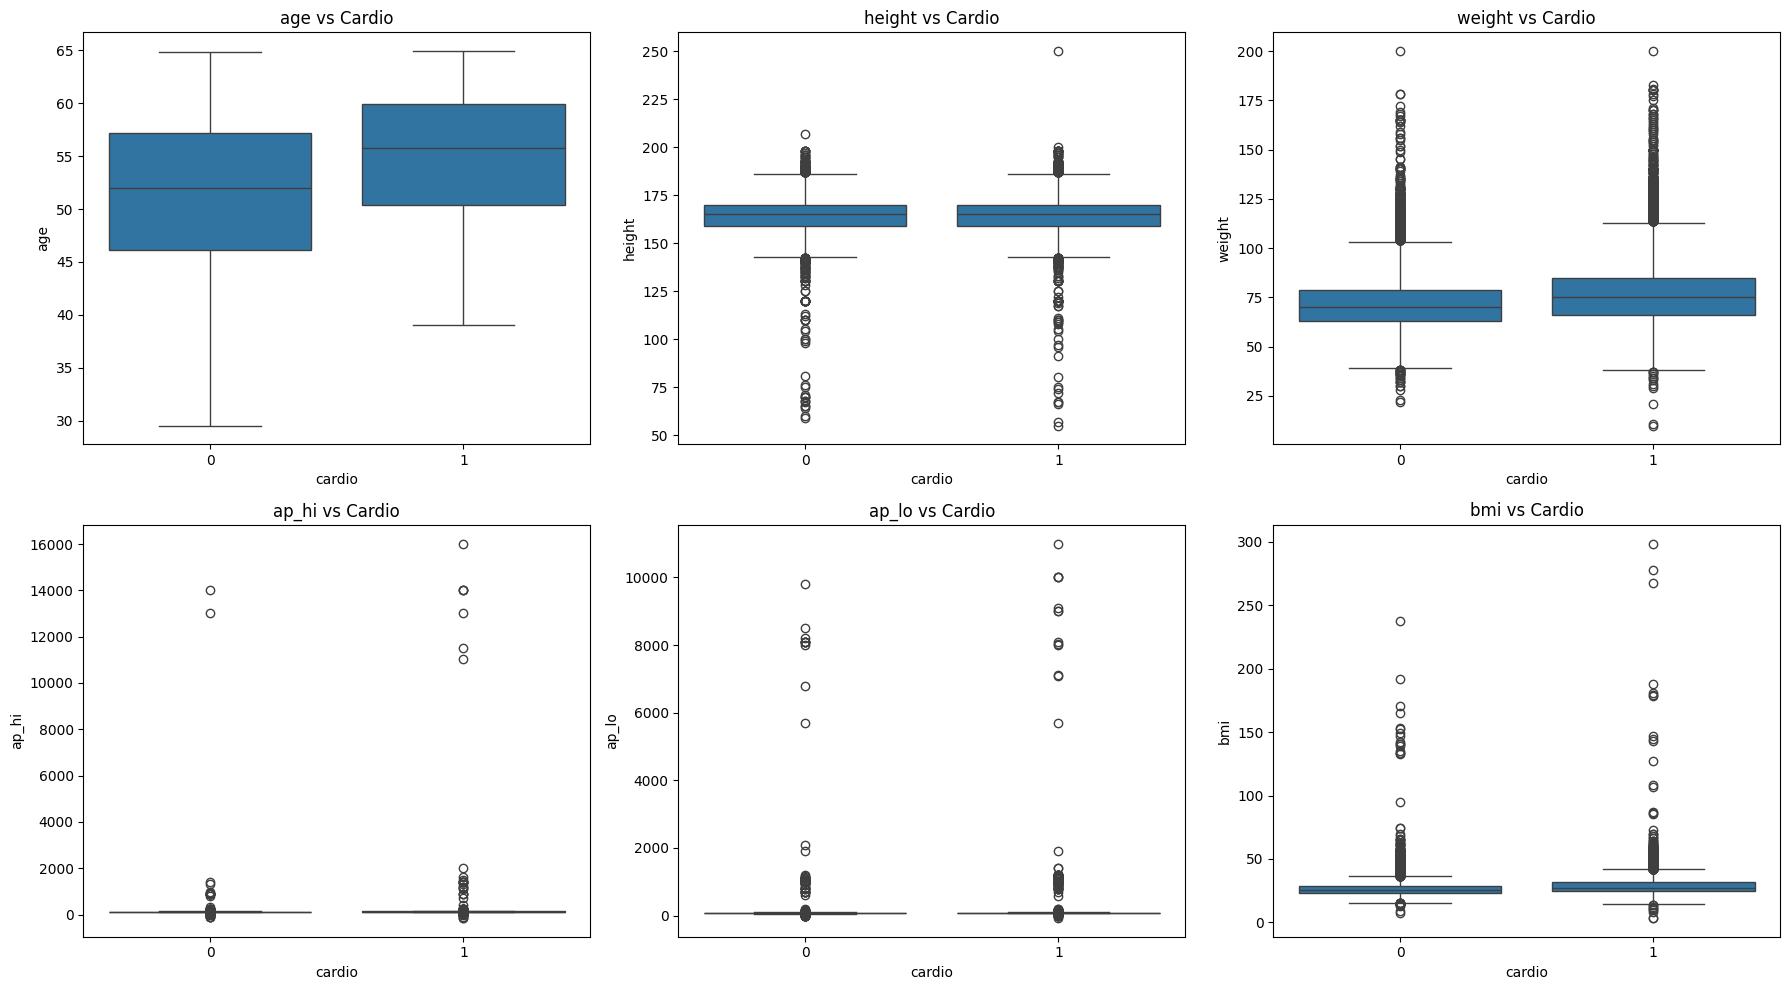

In [71]:
num_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(num_cols):
    sns.boxplot(data=dfc, x='cardio', y=col, ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(f'{col} vs Cardio')

plt.tight_layout()
plt.show()

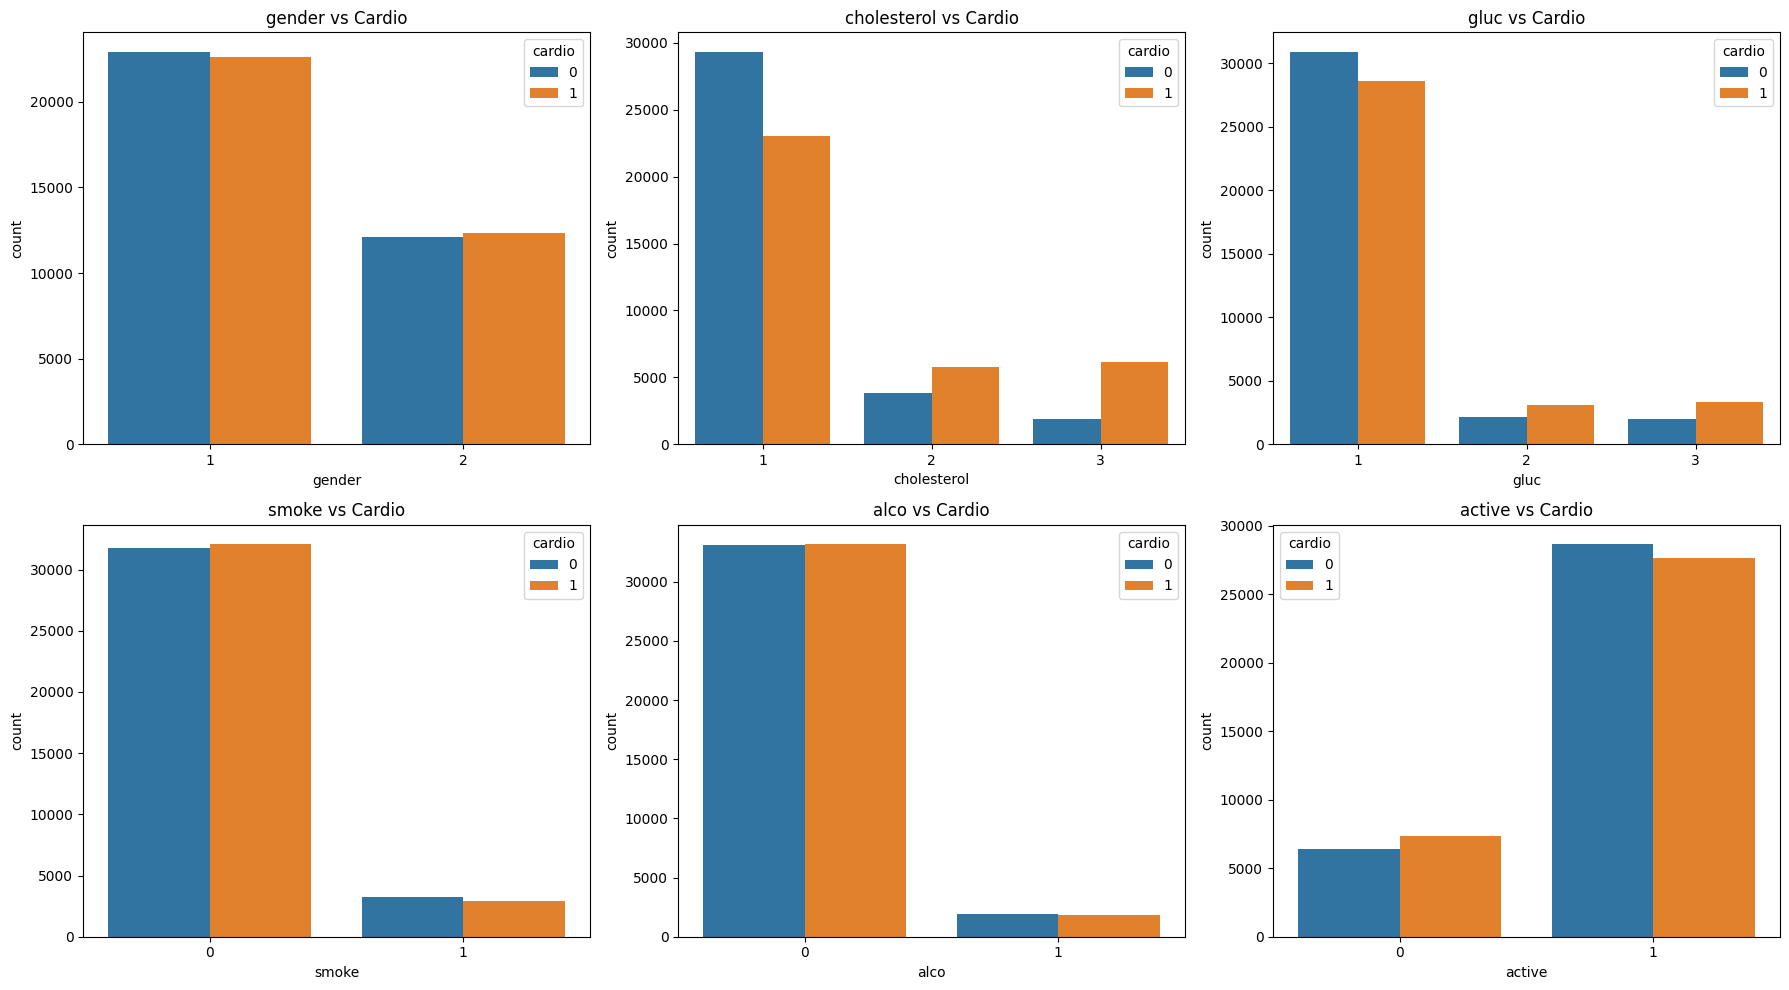

In [72]:
cat_cols = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(cat_cols):
    sns.countplot(data=dfc, x=col, hue='cardio', ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(f'{col} vs Cardio')

plt.tight_layout()
plt.show()

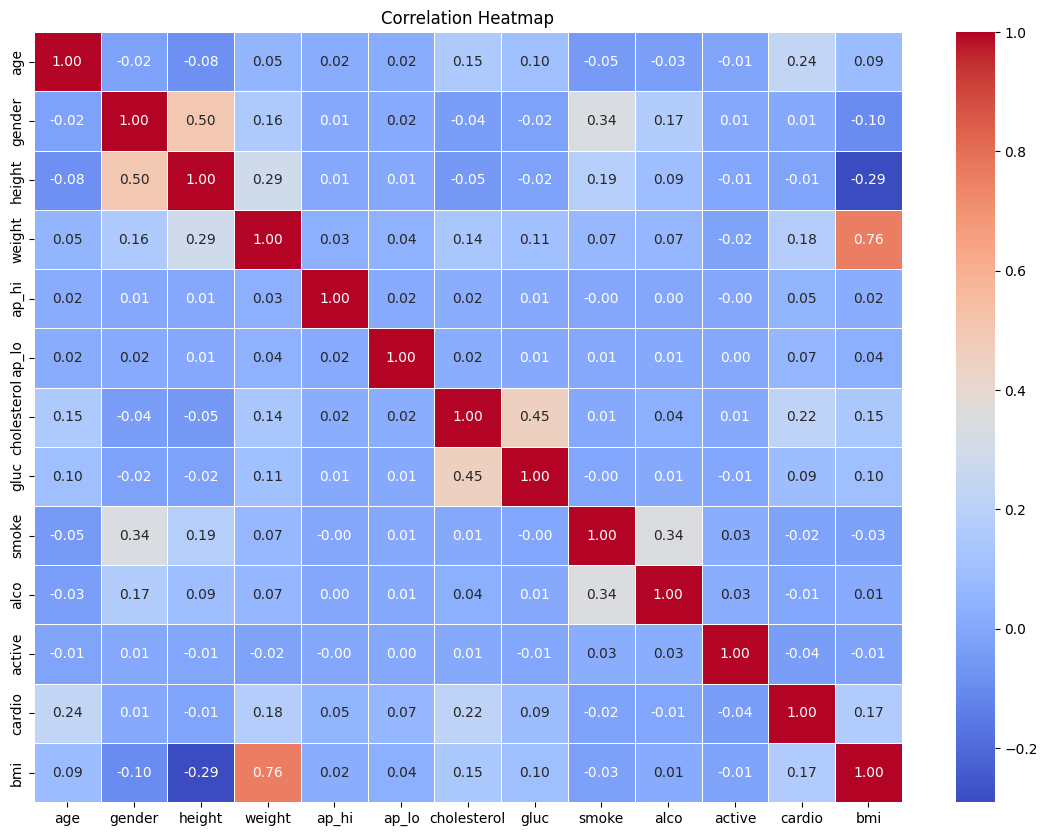

In [73]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    dfc.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [74]:
X = dfc.drop(columns=['cardio'])
y = dfc['cardio']

In [75]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y,test_size=0.2, random_state=42, stratify=y)

In [76]:
num_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi']

cat_cols = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('nominal', OneHotEncoder(drop='first', handle_unknown='ignore'),
         ['gender', 'smoke', 'alco', 'active']),
        ('ordinal', OrdinalEncoder(
            categories=[[1, 2, 3], [1, 2, 3]]
        ), ['cholesterol', 'gluc'])
    ],
    remainder='drop'
)

In [78]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [79]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, random_state=42)

In [80]:
lr.fit(X_train_transformed, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [81]:
y_pred = lr.predict(X_test_transformed)
y_prob = lr.predict_proba(X_test_transformed)[:, 1]

In [83]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
f1_score, confusion_matrix, classification_report, roc_auc_score)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7130714285714286
Precision: 0.7305370685652376
Recall: 0.6746712407089765
F1 Score: 0.7014936464293676
ROC AUC: 0.777986223424073


In [84]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.70      0.75      0.72      7004
           1       0.73      0.67      0.70      6996

    accuracy                           0.71     14000
   macro avg       0.71      0.71      0.71     14000
weighted avg       0.71      0.71      0.71     14000



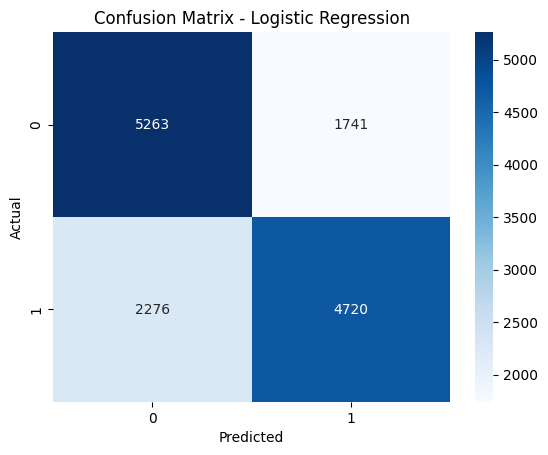

In [85]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')

plt.show()

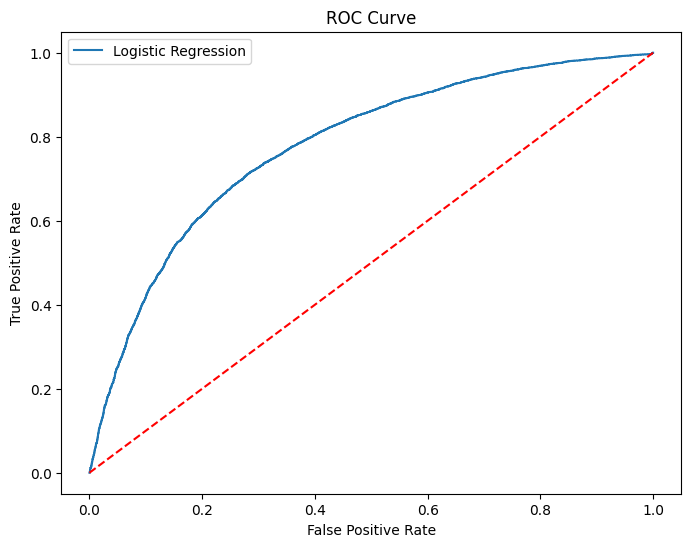

In [86]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', color='red')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [93]:
num_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi']

outlier_info = []

for col in num_cols:

    Q1 = dfc[col].quantile(0.25)
    Q3 = dfc[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((dfc[col] < lower) | (dfc[col] > upper)).sum()

    outlier_info.append({
        'Feature': col,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outliers': count,
        'Percentage': count / len(dfc) * 100
    })

    dfc[col] = dfc[col].clip(lower=lower, upper=upper)

outlier_df = pd.DataFrame(outlier_info)

outlier_df.round(2)

,Feature,Lower Bound,Upper Bound,Outliers,Percentage
0,age,33.32,73.44,4,0.01
1,height,142.50,186.50,519,0.74
2,weight,39.50,107.50,1819,2.60
3,ap_hi,90.00,170.00,1435,2.05
4,ap_lo,65.00,105.00,4632,6.62
5,bmi,14.35,39.74,1995,2.85


In [94]:
dfc

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi
0,50.36,2,168.0,62.0,110,80,1,1,0,0,1,0,21.967120
1,55.38,1,156.0,85.0,140,90,3,1,0,0,1,1,34.927679
2,51.63,1,165.0,64.0,130,70,3,1,0,0,0,1,23.507805
3,48.25,2,169.0,82.0,150,100,1,1,0,0,1,1,28.710479
4,47.84,1,156.0,56.0,100,65,1,1,0,0,0,0,23.011177
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,52.68,2,168.0,76.0,120,80,1,1,1,0,1,0,26.927438
69996,61.88,1,158.0,107.5,140,90,2,2,0,0,1,1,39.742883
69997,52.20,2,183.0,105.0,170,90,3,1,0,1,0,1,31.353579
69998,61.41,1,163.0,72.0,135,80,1,2,0,0,0,1,27.099251


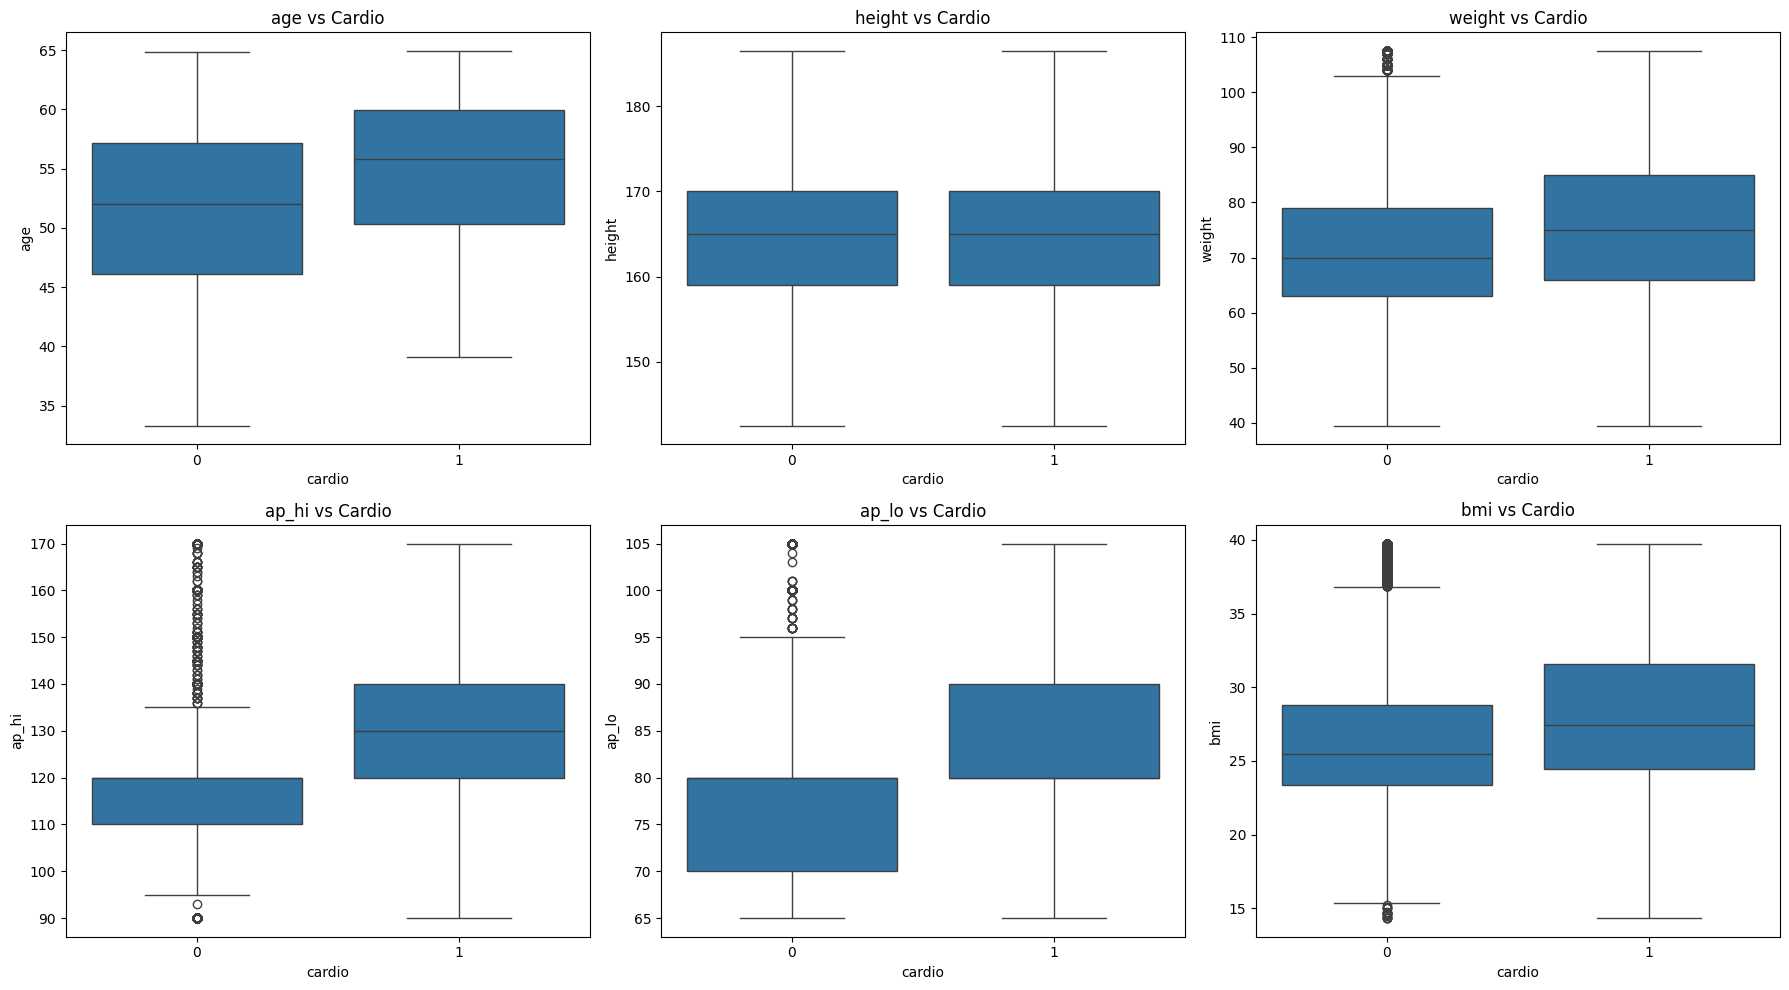

In [95]:
num_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(num_cols):
    sns.boxplot(data=dfc, x='cardio', y=col, ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(f'{col} vs Cardio')

plt.tight_layout()
plt.show()

In [96]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Naive Bayes': GaussianNB(),
    'XGBoost' :  XGBClassifier(n_estimators=200,learning_rate=0.05,max_depth=4,random_state=42,eval_metric='logloss', tree_method = 'hist')
}

In [97]:
import pandas as pd
import numpy as np
from scipy.sparse import issparse

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Convert sparse matrices to dense if required
Xtr = X_train_transformed.toarray() if issparse(X_train_transformed) else X_train_transformed
Xte = X_test_transformed.toarray() if issparse(X_test_transformed) else X_test_transformed

results = []

for name, model in models.items():

    # Training
    model.fit(Xtr, y_train)

    # Predictions
    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]

    # Evaluation
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='ROC AUC',
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,XGBoost,0.7351,0.7532,0.6988,0.7250,0.8007
1,Gradient Boosting,0.7335,0.7505,0.6991,0.7239,0.7995
2,AdaBoost,0.7224,0.7593,0.6509,0.7009,0.7891
3,SVM,0.7289,0.7408,0.7038,0.7218,0.7864
4,Logistic Regression,0.7131,0.7305,0.6747,0.7015,0.7780
5,Random Forest,0.7129,0.7157,0.7057,0.7107,0.7730
6,KNN,0.6445,0.6493,0.6276,0.6383,0.6861
7,Naive Bayes,0.5969,0.7106,0.3263,0.4473,0.6848
8,Decision Tree,0.6310,0.6292,0.6371,0.6331,0.6308


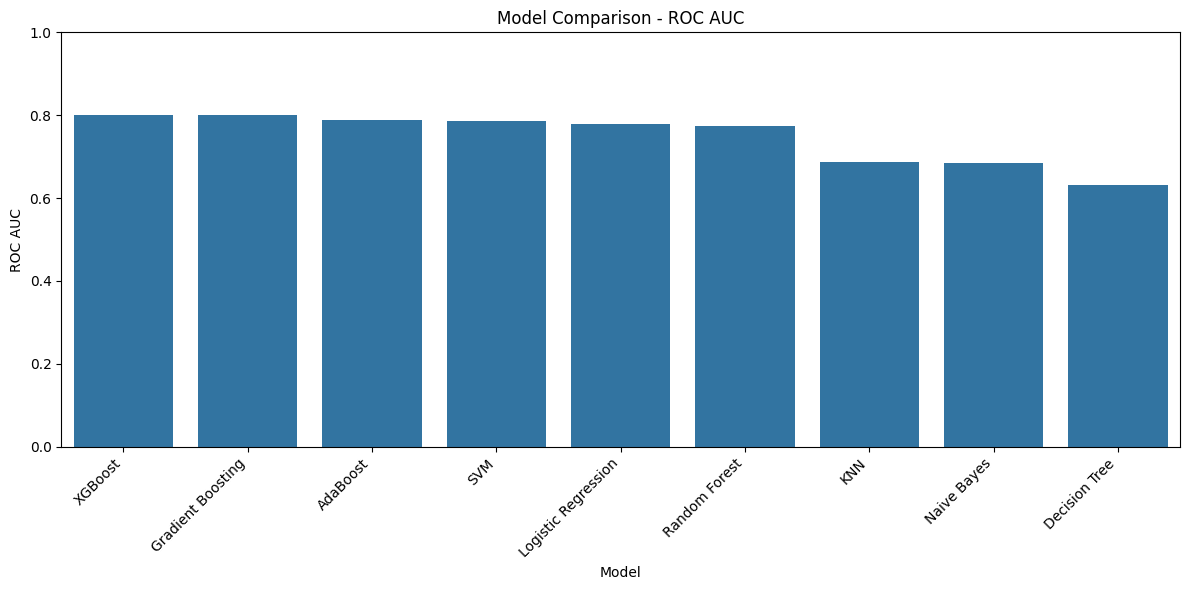

In [98]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='ROC AUC'
)

plt.xticks(rotation=45, ha='right')
plt.title('Model Comparison - ROC AUC')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [99]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [101]:
# cv_results = []

# for name, model in models.items():

#     pipe = Pipeline([
#         ('preprocessor', preprocessor),
#         ('classifier', model)
#     ])

#     scores = cross_validate(
#         pipe,
#         X_train,
#         y_train,
#         cv=cv,
#         scoring={
#             'accuracy': 'accuracy',
#             'precision': 'precision',
#             'recall': 'recall',
#             'f1': 'f1',
#             'roc_auc': 'roc_auc'
#         },
#         return_train_score=True,
#         n_jobs=-1
#     )

#     cv_results.append({
#         'Model': name,
#         'Accuracy': scores['test_accuracy'].mean(),
#         'Precision': scores['test_precision'].mean(),
#         'Recall': scores['test_recall'].mean(),
#         'F1': scores['test_f1'].mean(),
#         'ROC AUC': scores['test_roc_auc'].mean(),
#         'ROC AUC Std': scores['test_roc_auc'].std(),
#         'Train ROC AUC': scores['train_roc_auc'].mean()
#     })

# cv_df = pd.DataFrame(cv_results)

# cv_df = cv_df.sort_values(
#     by='ROC AUC',
#     ascending=False
# ).reset_index(drop=True)

# cv_df.round(4)

In [102]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

xgb_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        tree_method='hist'
    ))
])

In [103]:
xgb_params = {
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__max_depth': [2, 3, 4, 5, 6, 8],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'classifier__subsample': [0.7, 0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'classifier__min_child_weight': [1, 3, 5, 7],
    'classifier__gamma': [0, 0.1, 0.2, 0.5],
    'classifier__reg_lambda': [1, 5, 10]
}

In [104]:
xgb_random = RandomizedSearchCV(
    estimator=xgb_pipe,
    param_distributions=xgb_params,
    n_iter=40,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

xgb_random.fit(X_train, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               StandardScaler(),
                                                                               ['age',
                                                                                'height',
                                                                                'weight',
                                                                                'ap_hi',
                                                                                'ap_lo',
                                                                                'bmi']),
                                                                              ('nominal',
                                                                               OneHotEncoder(drop='first',
                                                                                             handle_unknown='ignore'),
                                                                               ['gender',
                                                                                'smoke',
                                                                                'alco',
                                                                                'active']),
                                                                              ('ordinal',
                                                                               OrdinalEncoder...
                   param_distributions={'classifier__colsample_bytree': [0.7,
                                                                         0.8,
                                                                         0.9,
                                                                         1.0],
                                        'classifier__gamma': [0, 0.1, 0.2, 0.5],
                                        'classifier__learning_rate': [0.01,
                                                                      0.03,
                                                                      0.05, 0.1,
                                                                      0.2],
                                        'classifier__max_depth': [2, 3, 4, 5, 6,
                                                                  8],
                                        'classifier__min_child_weight': [1, 3,
                                                                         5, 7],
                                        'classifier__n_estimators': [100, 200,
                                                                     300, 500],
                                        'classifier__reg_lambda': [1, 5, 10],
                                        'classifier__subsample': [0.7, 0.8, 0.9,
                                                                  1.0]},
                   random_state=42, scoring='roc_auc', verbose=1)

In [105]:
print("Best Parameters:")
print(xgb_random.best_params_)

print("Best CV ROC AUC:")
print(xgb_random.best_score_)

Best Parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 5, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 1, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.03, 'classifier__gamma': 0.5, 'classifier__colsample_bytree': 0.9}
Best CV ROC AUC:
0.804145981876317


In [106]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

best_xgb = xgb_random.best_estimator_

y_pred = best_xgb.predict(X_test)
y_prob = best_xgb.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7367857142857143
Precision: 0.7569455222722334
Recall: 0.6971126357918811
F1 Score: 0.7257980504501823
ROC AUC: 0.8009330166311892

Classification Report:

              precision    recall  f1-score   support

           0       0.72      0.78      0.75      7004
           1       0.76      0.70      0.73      6996

    accuracy                           0.74     14000
   macro avg       0.74      0.74      0.74     14000
weighted avg       0.74      0.74      0.74     14000


Confusion Matrix:

[[5438 1566]
 [2119 4877]]


In [107]:
xgb_model = best_xgb.named_steps['classifier']

# Get feature names after preprocessing
feature_names = best_xgb.named_steps['preprocessor'].get_feature_names_out()

# Create importance DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
3,num__ap_hi,0.548916
10,ordinal__cholesterol,0.128123
0,num__age,0.083120
4,num__ap_lo,0.075221
9,nominal__active_1,0.032620
7,nominal__smoke_1,0.029959
5,num__bmi,0.021561
11,ordinal__gluc,0.020383
2,num__weight,0.019904
8,nominal__alco_1,0.017079


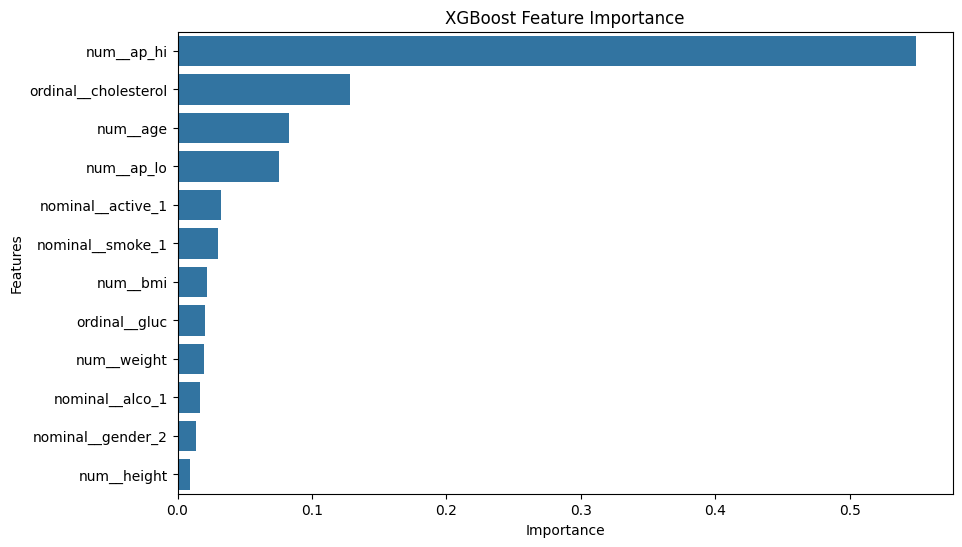

In [108]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')

plt.show()

In [109]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_xgb,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm.importances_mean,
    'Std': perm.importances_std
}).sort_values(by='Importance', ascending=False)

perm_df

,Feature,Importance,Std
4,ap_hi,0.171744,0.004553
0,age,0.036377,0.001542
6,cholesterol,0.028585,0.001064
5,ap_lo,0.004732,0.000581
11,bmi,0.002694,0.000598
10,active,0.002333,0.000255
7,gluc,0.002155,0.000151
3,weight,0.001826,0.000424
8,smoke,0.000746,0.000132
9,alco,0.000542,0.000120


In [110]:
top_8 = [
    'ap_hi', 'age', 'cholesterol', 'ap_lo',
    'bmi', 'active', 'gluc', 'weight'
]

top_5 = [
    'ap_hi', 'age', 'cholesterol', 'ap_lo', 'bmi'
]

X_train_8 = X_train[top_8]
X_test_8 = X_test[top_8]

X_train_5 = X_train[top_5]
X_test_5 = X_test[top_5]

In [116]:
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

def evaluate_features(Xtr, Xte):

    num_cols = [
        col for col in ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi']
        if col in Xtr.columns
    ]

    nominal_cols = [
        col for col in ['gender', 'smoke', 'alco', 'active']
        if col in Xtr.columns
    ]

    ordinal_cols = [
        col for col in ['cholesterol', 'gluc']
        if col in Xtr.columns
    ]

    transformers = []

    if num_cols:
        transformers.append(
            ('num', StandardScaler(), num_cols)
        )

    if nominal_cols:
        transformers.append(
            ('nominal', OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ), nominal_cols)
        )

    if ordinal_cols:
        transformers.append(
            ('ordinal', OrdinalEncoder(
                categories=[[1, 2, 3] for _ in ordinal_cols]
            ), ordinal_cols)
        )

    prep = ColumnTransformer(
        transformers=transformers,
        remainder='drop'
    )

    model = Pipeline([
        ('preprocessor', prep),
        ('classifier', XGBClassifier(
            **{
                key.replace('classifier__', ''): value
                for key, value in xgb_random.best_params_.items()
            },
            random_state=42,
            eval_metric='logloss',
            n_jobs=1
        ))
    ])

    model.fit(Xtr, y_train)

    y_prob = model.predict_proba(Xte)[:, 1]

    return roc_auc_score(y_test, y_prob)

In [117]:
scores = {
    'All 12 Features': evaluate_features(X_train, X_test),
    'Top 8 Features': evaluate_features(X_train_8, X_test_8),
    'Top 5 Features': evaluate_features(X_train_5, X_test_5)
}

pd.DataFrame(
    list(scores.items()),
    columns=['Feature Set', 'ROC AUC']
).sort_values('ROC AUC', ascending=False)

,Feature Set,ROC AUC
0,All 12 Features,0.800933
1,Top 8 Features,0.799654
2,Top 5 Features,0.796133


In [118]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.1, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, y_pred_threshold),
        'Precision': precision_score(y_test, y_pred_threshold),
        'Recall': recall_score(y_test, y_pred_threshold),
        'F1 Score': f1_score(y_test, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.10,0.5254,0.5129,0.9971,0.6774
1,0.15,0.5626,0.5338,0.9843,0.6922
2,0.20,0.6009,0.5582,0.9656,0.7074
3,0.25,0.6469,0.5939,0.9272,0.7241
4,0.30,0.6848,0.6331,0.8779,0.7357
5,0.35,0.7080,0.6641,0.8411,0.7422
6,0.40,0.7262,0.7030,0.7827,0.7408
7,0.45,0.7335,0.7293,0.7423,0.7357
8,0.50,0.7368,0.7569,0.6971,0.7258
9,0.55,0.7334,0.7816,0.6475,0.7083


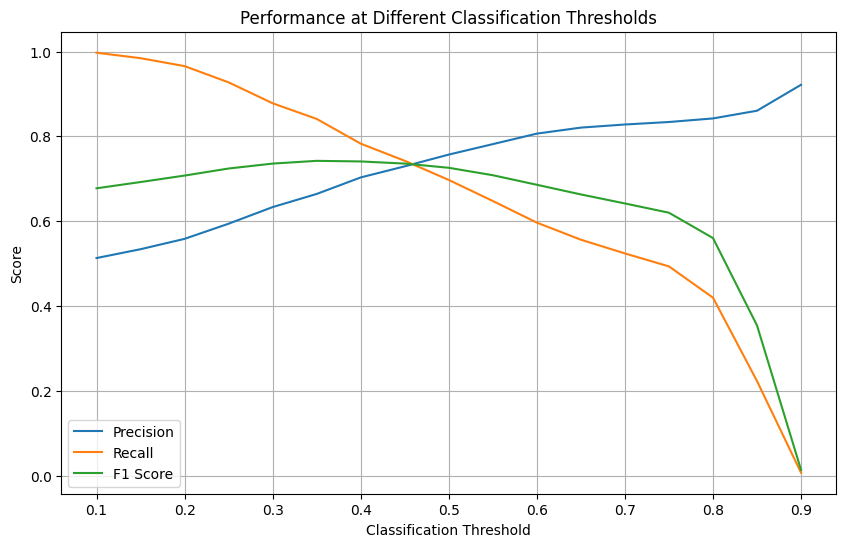

In [119]:
plt.figure(figsize=(10, 6))

plt.plot(threshold_df['Threshold'], threshold_df['Precision'], label='Precision')
plt.plot(threshold_df['Threshold'], threshold_df['Recall'], label='Recall')
plt.plot(threshold_df['Threshold'], threshold_df['F1 Score'], label='F1 Score')

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Performance at Different Classification Thresholds')

plt.legend()
plt.grid()
plt.show()

In [120]:
best_xgb.set_params(classifier__n_jobs=1)

oof_prob = cross_val_predict(
    best_xgb,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

thresholds = np.arange(0.20, 0.71, 0.01)

results = []

for t in thresholds:
    pred = (oof_prob >= t).astype(int)

    results.append({
        'Threshold': t,
        'Precision': precision_score(y_train, pred),
        'Recall': recall_score(y_train, pred),
        'F1': f1_score(y_train, pred)
    })

oof_threshold_df = pd.DataFrame(results)

oof_threshold_df.sort_values(
    'F1', ascending=False
).head(10)

,Threshold,Precision,Recall,F1
18,0.38,0.689769,0.804488,0.742725
19,0.39,0.698124,0.792803,0.742457
16,0.36,0.673529,0.826609,0.742258
15,0.35,0.666344,0.837437,0.742158
17,0.37,0.680951,0.815424,0.742145
14,0.34,0.660388,0.846943,0.742121
20,0.40,0.705443,0.782761,0.742093
21,0.41,0.711681,0.774041,0.741552
13,0.33,0.653984,0.855019,0.741110
22,0.42,0.718346,0.764143,0.740537


In [121]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

final_threshold = 0.38

y_test_prob = best_xgb.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_prob >= final_threshold
).astype(int)

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1:", f1_score(y_test, y_test_pred))
print("ROC AUC:", roc_auc_score(y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Accuracy: 0.7192857142857143
Precision: 0.6871794871794872
Recall: 0.8044596912521441
F1: 0.7412090082971158
ROC AUC: 0.8009330166311892

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.63      0.69      7004
           1       0.69      0.80      0.74      6996

    accuracy                           0.72     14000
   macro avg       0.73      0.72      0.72     14000
weighted avg       0.73      0.72      0.72     14000


Confusion Matrix:
[[4442 2562]
 [1368 5628]]


In [122]:
print(dfc['cardio'].value_counts())

print("\nPercentage distribution:")
print(
    (dfc['cardio'].value_counts(normalize=True) * 100).round(2)
)

cardio
0    35021
1    34979
Name: count, dtype: int64

Percentage distribution:
cardio
0    50.03
1    49.97
Name: proportion, dtype: float64


In [123]:
import joblib

joblib.dump(best_xgb, 'cardio_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [124]:
joblib.dump(final_threshold, 'threshold.pkl')

['threshold.pkl']

In [125]:
loaded_model = joblib.load('cardio_model.pkl')

loaded_threshold = joblib.load('threshold.pkl')

# Make predictions
probabilities = loaded_model.predict_proba(X_test)[:, 1]

predictions = (probabilities >= loaded_threshold).astype(int)

print(predictions[:10])

[0 1 0 0 0 1 1 0 0 1]


In [126]:
print(np.array_equal(predictions, y_test_pred))

True


In [127]:
dfc.to_csv('cardio_cleaned.csv', index=False)
dfc = pd.read_csv('cardio_cleaned.csv')